# Preprocesado y extracción de características

1. Se cargan las imágenes de las 6 clases en arrays (`X`, `y`) y se preprocesan.
2. Se calculan dos descriptores: HOG y LBP.
3. Se guardan en `data/` para el entrenamiento.

El preprocesado y las características están en `emociones_utils.py`, que también usa el prototipo, para que la cara de la webcam se procese igual que las de entrenamiento.

In [ ]:
import os, sys
from pathlib import Path

# Los notebooks están en notebooks/, se trabaja desde la carpeta del proyecto
if not Path("emociones_utils.py").exists():
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import time
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.feature import hog, local_binary_pattern

from emociones_utils import CLASES, NOMBRE_ES, preprocesar, extraer, HOG_PARAMS, LBP_P, LBP_R

RUTA_LOCAL = "data/fer2013"
CACHE_IMAGENES = "data/fer6_preprocesado.npz"
CACHE_CARACT = "data/fer6_caracteristicas.npz"

Path("data").mkdir(exist_ok=True)
print("Clases:", {i: NOMBRE_ES[c] for i, c in enumerate(CLASES)})

Clases: {0: 'enfado', 1: 'miedo', 2: 'feliz', 3: 'neutral', 4: 'triste', 5: 'sorpresa'}


## Carga y preprocesado
Cada imagen se guarda como una matriz 48×48 y su etiqueta como el índice de la clase. Como leer ~35.000 archivos tarda, el resultado se guarda en un `.npz` y las siguientes veces se carga de ahí.

In [2]:
def buscar_raiz(carpeta):
    carpeta = Path(carpeta)
    for candidata in [carpeta, *carpeta.glob("*"), *carpeta.glob("*/*")]:
        if (candidata / "train").is_dir() and (candidata / "test").is_dir():
            return candidata
    raise FileNotFoundError(f"No se encuentra train/ y test/ en {carpeta.resolve()}")

def obtener_raiz():
    if Path(RUTA_LOCAL).exists():
        return buscar_raiz(RUTA_LOCAL)
    import kagglehub
    return buscar_raiz(kagglehub.dataset_download("msambare/fer2013"))

def leer_gris(ruta):
    return cv2.imdecode(np.fromfile(str(ruta), dtype=np.uint8), cv2.IMREAD_GRAYSCALE)

def cargar_split(raiz, split):
    X, y = [], []
    for etiqueta, clase in enumerate(CLASES):
        rutas = sorted((raiz / split / clase).glob("*"))
        for r in rutas:
            X.append(preprocesar(leer_gris(r)))
            y.append(etiqueta)
        print(f"  {split:5s} {clase:9s} {len(rutas):5d}")
    return np.array(X, dtype=np.uint8), np.array(y, dtype=np.int64)

if Path(CACHE_IMAGENES).exists():
    d = np.load(CACHE_IMAGENES)
    X_train, y_train, X_test, y_test = d["X_train"], d["y_train"], d["X_test"], d["y_test"]
    print("Cargado desde", CACHE_IMAGENES)
else:
    t0 = time.time()
    raiz = obtener_raiz()
    X_train, y_train = cargar_split(raiz, "train")
    X_test, y_test = cargar_split(raiz, "test")
    np.savez_compressed(CACHE_IMAGENES, X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test)
    print(f"Guardado en {CACHE_IMAGENES} ({time.time() - t0:.0f} s)")

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test: ", X_test.shape, " y_test: ", y_test.shape)

c:\Users\becha\anaconda3\envs\VC_P5\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  train angry      3995
  train fear       4097
  train happy      7215
  train neutral    4965
  train sad        4830
  train surprise   3171
  test  angry       958
  test  fear       1024
  test  happy      1774
  test  neutral    1233
  test  sad        1247
  test  surprise    831
Guardado en data/fer6_preprocesado.npz (16 s)
X_train: (28273, 48, 48)  y_train: (28273,)
X_test:  (7067, 48, 48)  y_test:  (7067,)


## Preprocesado
Se redimensiona a 48×48 y se ecualiza el histograma (`cv2.equalizeHist`) para que todas las caras tengan un contraste parecido. Esto reduce la diferencia de iluminación entre las imágenes del dataset y las de la webcam.

In [ ]:
raiz = obtener_raiz()
rutas = [sorted((raiz / "train" / c).glob("*"))[7] for c in CLASES]

fig, ejes = plt.subplots(2, len(rutas), figsize=(len(rutas) * 1.6, 3.6))
for i, r in enumerate(rutas):
    orig = leer_gris(r)
    ejes[0, i].imshow(orig, cmap="gray", vmin=0, vmax=255)
    ejes[0, i].set_title(NOMBRE_ES[CLASES[i]], fontsize=9)
    ejes[1, i].imshow(preprocesar(orig), cmap="gray", vmin=0, vmax=255)
    ejes[0, i].axis("off"); ejes[1, i].axis("off")
ejes[0, 0].text(-8, 24, "original", rotation=90, va="center")
ejes[1, 0].text(-8, 24, "ecualizada", rotation=90, va="center")
plt.tight_layout(); plt.show()

## HOG
El histograma de gradientes orientados describe los bordes de la imagen, es decir, la forma de boca, ojos y cejas:

1. Se calcula el gradiente de cada píxel (dirección e intensidad del cambio).
2. La imagen se divide en celdas de 8×8 px (6×6 celdas).
3. En cada celda se hace un histograma de 9 orientaciones.
4. Las celdas se agrupan en bloques de 2×2 y se normalizan para reducir el efecto de la iluminación.

Resultado: 5×5 bloques × 4 celdas × 9 orientaciones = 900 valores.

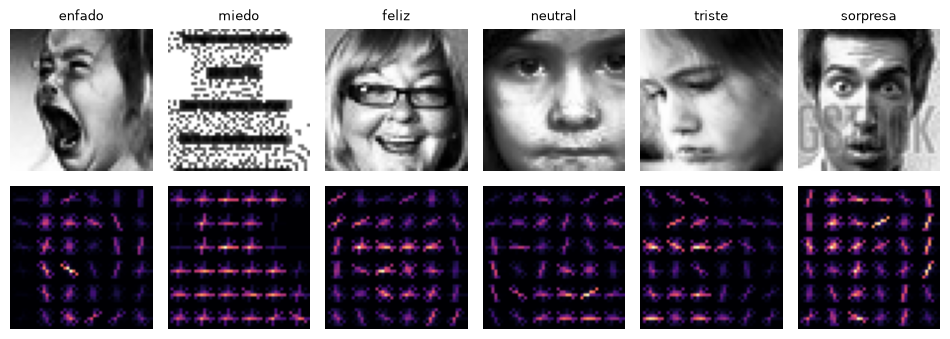

Longitud del vector HOG: 900


In [4]:
fig, ejes = plt.subplots(2, len(CLASES), figsize=(len(CLASES) * 1.6, 3.6))
for i in range(len(CLASES)):
    img = X_train[np.where(y_train == i)[0][7]]
    _, vis = hog(img, visualize=True, **HOG_PARAMS)
    ejes[0, i].imshow(img, cmap="gray"); ejes[0, i].set_title(NOMBRE_ES[CLASES[i]], fontsize=9)
    ejes[1, i].imshow(vis, cmap="magma")
    ejes[0, i].axis("off"); ejes[1, i].axis("off")
plt.tight_layout(); plt.show()

print("Longitud del vector HOG:", extraer(X_train[0], "hog").shape[0])

## LBP
Los patrones binarios locales describen la textura: cada píxel se compara con sus 8 vecinos y se obtiene un código. Con el método `uniform` los códigos se agrupan en 10 tipos, y se calcula su histograma en cada celda de 8×8.

Resultado: 36 celdas × 10 = 360 valores. HOG recoge formas y LBP texturas, por eso también se probarán juntos.

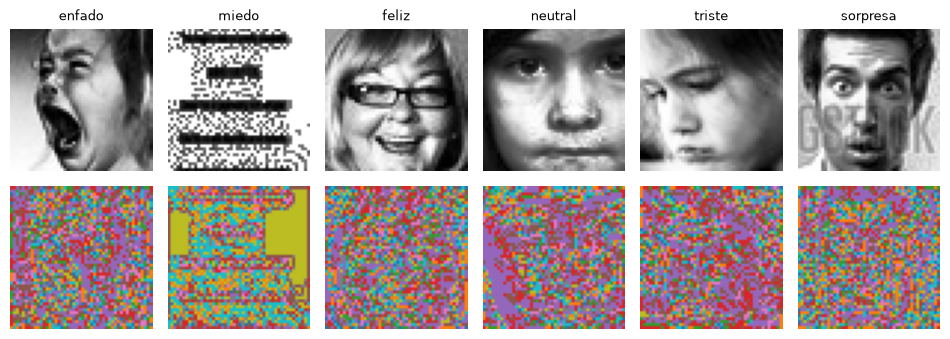

Longitud del vector LBP: 360


In [5]:
fig, ejes = plt.subplots(2, len(CLASES), figsize=(len(CLASES) * 1.6, 3.6))
for i in range(len(CLASES)):
    img = X_train[np.where(y_train == i)[0][7]]
    codigos = local_binary_pattern(img, LBP_P, LBP_R, method="uniform")
    ejes[0, i].imshow(img, cmap="gray"); ejes[0, i].set_title(NOMBRE_ES[CLASES[i]], fontsize=9)
    ejes[1, i].imshow(codigos, cmap="tab10")
    ejes[0, i].axis("off"); ejes[1, i].axis("off")
plt.tight_layout(); plt.show()

print("Longitud del vector LBP:", extraer(X_train[0], "lbp").shape[0])

## Extracción para todo el dataset
Los píxeles no se guardan porque se obtienen directamente de `X_train`.

In [6]:
def extraer_todo(X, tipo):
    return np.stack([extraer(img, tipo) for img in X])

if Path(CACHE_CARACT).exists():
    print("Ya existen las características en", CACHE_CARACT, "(bórralo si cambias los parámetros)")
else:
    caract = {}
    for tipo in ["hog", "lbp"]:
        t0 = time.time()
        caract[f"{tipo}_train"] = extraer_todo(X_train, tipo)
        caract[f"{tipo}_test"] = extraer_todo(X_test, tipo)
        print(f"{tipo.upper():4s} train {caract[f'{tipo}_train'].shape}  test {caract[f'{tipo}_test'].shape}  ({time.time() - t0:.0f} s)")
    np.savez_compressed(CACHE_CARACT, y_train=y_train, y_test=y_test, **caract)
    print("Guardado en", CACHE_CARACT)

HOG  train (28273, 900)  test (7067, 900)  (14 s)
LBP  train (28273, 360)  test (7067, 360)  (51 s)
Guardado en data/fer6_caracteristicas.npz


## Observaciones

- HOG da 900 valores, LBP 360 y los píxeles 2304. Más valores no implica mejores resultados: muchos píxeles no aportan nada a la emoción (fondo, pelo) y cambian si la cara se desplaza un poco, mientras que HOG resume la forma por zonas.
- En la visualización de HOG los bordes más marcados están en cejas, ojos y boca, las mismas zonas que cambiaban en las diferencias de caras medias.
- Con `pixels_per_cell=(6, 6)` habría 8×8 celdas y 1764 valores: más detalle, pero el doble de dimensión y más sensibilidad al ruido.